In [3]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision.transforms import v2
import matplotlib.pyplot as plt
from torch.utils.data import random_split
from torchvision.datasets import CIFAR10

In [4]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
print(f'using {device} device')
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
train_data = CIFAR10(root='data', train=True, download=True, transform=transform)
test_data = CIFAR10(root='data', train=False, download=True, transform=transform)

print(train_data.classes)
print(train_data.class_to_idx)



using cuda device
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
{'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}


In [5]:
train, valid = random_split(train_data, lengths=[45000, 5000], generator=torch.Generator().manual_seed(101))


In [6]:
train_dataloader_forminstd = DataLoader(train, batch_size=len(train), shuffle=False)
images, _ = next(iter(train_dataloader_forminstd))

mean = images.mean(dim=(0, 2, 3))         
std  = images.std(dim=(0, 2, 3))              
x_norm = (images - mean[None, :, None, None]) / std[None, :, None, None]
print(f"Обычный mean {mean}, x_norm: {x_norm.mean(dim=(0, 2, 3))}")   
print(f"Обычный std {std}, x_norm: {x_norm.std(dim=(0,2,3))}") 
del images, x_norm


Обычный mean tensor([0.4912, 0.4819, 0.4464]), x_norm: tensor([ 1.2374e-06, -4.5080e-06, -3.2374e-06])
Обычный std tensor([0.2471, 0.2435, 0.2615]), x_norm: tensor([1.0000, 1.0000, 1.0000])


In [7]:
norm_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=mean.tolist(), std=std.tolist()),
])

train_data.transform = norm_transform
test_data.transform = norm_transform

train_dataloader = DataLoader(train, batch_size=64, shuffle=True)
valid_dataloader = DataLoader(valid, batch_size=64, shuffle=False)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=False)


In [8]:
print(f"train: {len(train)}, valid: {len(valid)}, test: {len(test_data)}")

X, y = next(iter(train_dataloader))
print(X.shape, y.shape)
print('mean батча по каналам:', X.mean(dim=(0, 2, 3)))

train: 45000, valid: 5000, test: 10000
torch.Size([64, 3, 32, 32]) torch.Size([64])
mean батча по каналам: tensor([0.0570, 0.1036, 0.0770])


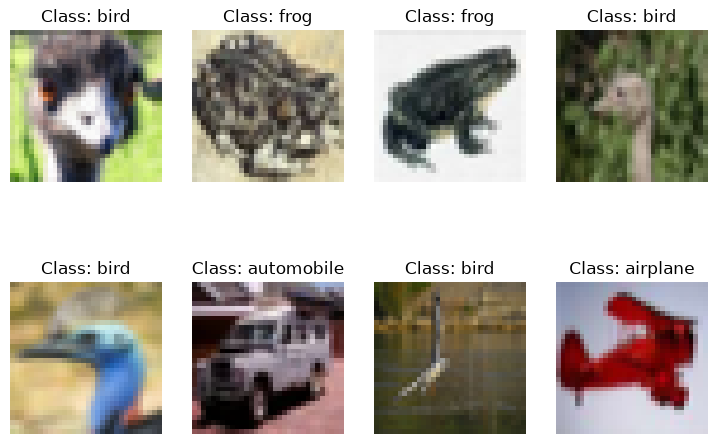

In [9]:
figure = plt.figure(figsize=(9, 6))
for i in range(1, 9):
    idx = torch.randint(len(train), size=(1,)).item()
    img, label = train[idx]
    
    true_name = train_data.classes[label]
    
    figure.add_subplot(2, 4, i)
    plt.title(f"Class: {true_name}")         
    plt.axis('off')
    img = img * std[:, None, None] + mean[:, None, None]
    img = img.clamp(min=0, max=1) 
    plt.imshow(img.permute(1, 2, 0))
plt.show()